# 三国人物关系图生成（Word2Vec + PCA）

基于《三国演义》全文，流程：**jieba 分词清洗 → Word2Vec 词嵌入 → PCA 降维 → 相似度连线可视化**。

依赖：`jieba`、`numpy`、`scikit-learn`、`gensim`、`matplotlib`（若缺失请先 `!pip install jieba gensim scikit-learn matplotlib`）。


## 0. 配置路径与导入

`BASE` 为语料目录（需包含 `sanguo.txt` 与字体文件 `华文仿宋.ttf`）。默认指向本实验目录；若把 notebook 与语料放在同一目录运行，会自动切换为当前目录。


In [1]:
import os
import jieba
import re
import json
import numpy as np
from sklearn.decomposition import PCA
from gensim.models import Word2Vec
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

BASE = r"C:\Users\叶湘伦\Desktop\2026-2027-1专业实习Transformers预训练模型\三国"
if not os.path.exists(os.path.join(BASE, "sanguo.txt")) and os.path.exists("sanguo.txt"):
    BASE = os.getcwd()
CORPUS = os.path.join(BASE, "sanguo.txt")
FONT = os.path.join(BASE, "华文仿宋.ttf")
OUT_PNG = os.path.join(BASE, "三国人物关系图.png")
OUT_JSON = os.path.join(BASE, "三国人物关系数据.json")
print("语料目录:", BASE)
print("语料存在:", os.path.exists(CORPUS))


语料目录: C:\Users\叶湘伦\Desktop\2026-2027-1专业实习Transformers预训练模型\三国
语料存在: True


## 1. 分词-清洗

逐行读取《三国演义》全文，用 jieba 分词并去除标点符号，得到二维词序列列表（与原始 notebook 完全一致）。


In [2]:
lines = []
with open(CORPUS, 'r', encoding='utf-8') as f:
    for line in f:
        temp = jieba.lcut(line)
        words = []
        for i in temp:
            i = re.sub("[\s+\.\!\/_,$%^*(+\"\']+|[+——！，。？、~@#￥%……&*（）：；‘’-]+", "", i)
            if len(i) > 0:
                words.append(i)
        if len(words) > 0:
            lines.append(words)
print("Res number:", len(lines))
print(lines[0:5])


Building prefix dict from the default dictionary ...
Loading model from cache C:\Users\叶湘伦\AppData\Local\Temp\jieba.cache
Loading model cost 0.673 seconds.
Prefix dict has been built successfully.


Res number: 1585
[['三国演义', '上卷'], ['罗贯中'], ['滚滚', '长江', '东', '逝水', '浪花', '淘尽', '英雄', '是非成败', '转头', '空', '青山', '依旧', '在', '几度', '夕阳红'], ['白发', '渔樵', '江渚上', '惯看', '秋月春风', '一壶', '浊酒', '喜相逢', '古今', '多少', '事', '都', '付笑谈', '中'], ['调寄', '《', '临江仙', '》']]


## 2. 训练词嵌入模型

参数与原始 notebook 一致：`vector_size=20`（词向量维度）、`window=2`（上下文窗口）、`min_count=3`（最低词频）、`epochs=7`、`negative=10`、`sg=1`（Skip-gram）。


In [3]:
model = Word2Vec(lines, vector_size=20, window=2, min_count=3, epochs=7, negative=10, sg=1)
print("词典大小:", len(model.wv.index_to_key))


词典大小: 12483


## 3. 选取三国人物并降维

按阵营选取 60 位主要人物（词频 <3 的人物不会出现在词表中，运行时会自动跳过并提示缺失）。将所有人物词向量用 **PCA 降维到 2 维**，得到可视化坐标。


In [4]:
characters = {
    "蜀汉": ["刘备", "诸葛亮", "关羽", "张飞", "赵云", "马超", "黄忠", "魏延",
             "庞统", "姜维", "刘禅", "马谡", "廖化", "法正", "马岱"],
    "曹魏": ["曹操", "司马懿", "曹丕", "曹植", "郭嘉", "荀彧", "贾诩", "张辽",
             "许褚", "典韦", "夏侯惇", "夏侯渊", "曹仁", "于禁", "徐晃"],
    "东吴": ["孙权", "周瑜", "鲁肃", "陆逊", "吕蒙", "孙坚", "孙策", "黄盖",
             "甘宁", "太史慈", "丁奉", "周泰", "程普", "韩当"],
    "群雄": ["吕布", "董卓", "袁绍", "袁术", "刘表", "刘璋", "张角", "貂蝉",
             "华雄", "颜良", "文丑", "陈宫", "马腾", "公孙瓒", "张鲁", "刘繇"],
}

present, missing = {}, []
for faction, names in characters.items():
    for n in names:
        if n in model.wv.index_to_key:
            present[n] = faction
        else:
            missing.append(n)
print("可用人物:", len(present), " 缺失(词频<3):", missing)

names = list(present.keys())
vecs = np.array([model.wv.get_vector(n) for n in names])
pca = PCA(n_components=2)
coords = pca.fit_transform(vecs)
print("PCA 方差解释率:", pca.explained_variance_ratio_)


可用人物: 60  缺失(词频<3): []
PCA 方差解释率: [0.37856552 0.16880728]


## 4. 人物相似度 → 关系连线

计算人物两两之间的**余弦相似度**；每个角色取与其最相似的 **K=2** 个角色，且相似度须超过阈值 **0.92**，生成关系连线。

> 注意：这里的关系是模型从语料共现中学到的**语义相似度**，不等于真实历史关系，个别连线可能不符合史实——这正是小维度词嵌入的特点。


In [5]:
def cos_sim(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-9))

sim_matrix = np.zeros((len(names), len(names)))
for i in range(len(names)):
    for j in range(len(names)):
        sim_matrix[i, j] = cos_sim(vecs[i], vecs[j])

K, THRESH = 2, 0.92
edges, edge_sims = set(), {}
for i in range(len(names)):
    sims = sorted([(sim_matrix[i, j], j) for j in range(len(names)) if j != i], reverse=True)
    for s, j in sims[:K]:
        if s >= THRESH:
            key = tuple(sorted([i, j]))
            edges.add(key)
            edge_sims[key] = max(edge_sims.get(key, 0.0), s)
print("生成关系连线:", len(edges), "条 (K=", K, ", 阈值=", THRESH, ")")


生成关系连线: 68 条 (K= 2 , 阈值= 0.92 )


## 5. 可视化：三国人物关系图

绘制星空图：浅灰点为全部词表词的 PCA 投影（背景），彩色点为三国人物（按阵营着色），连线为人物间的高相似关系。


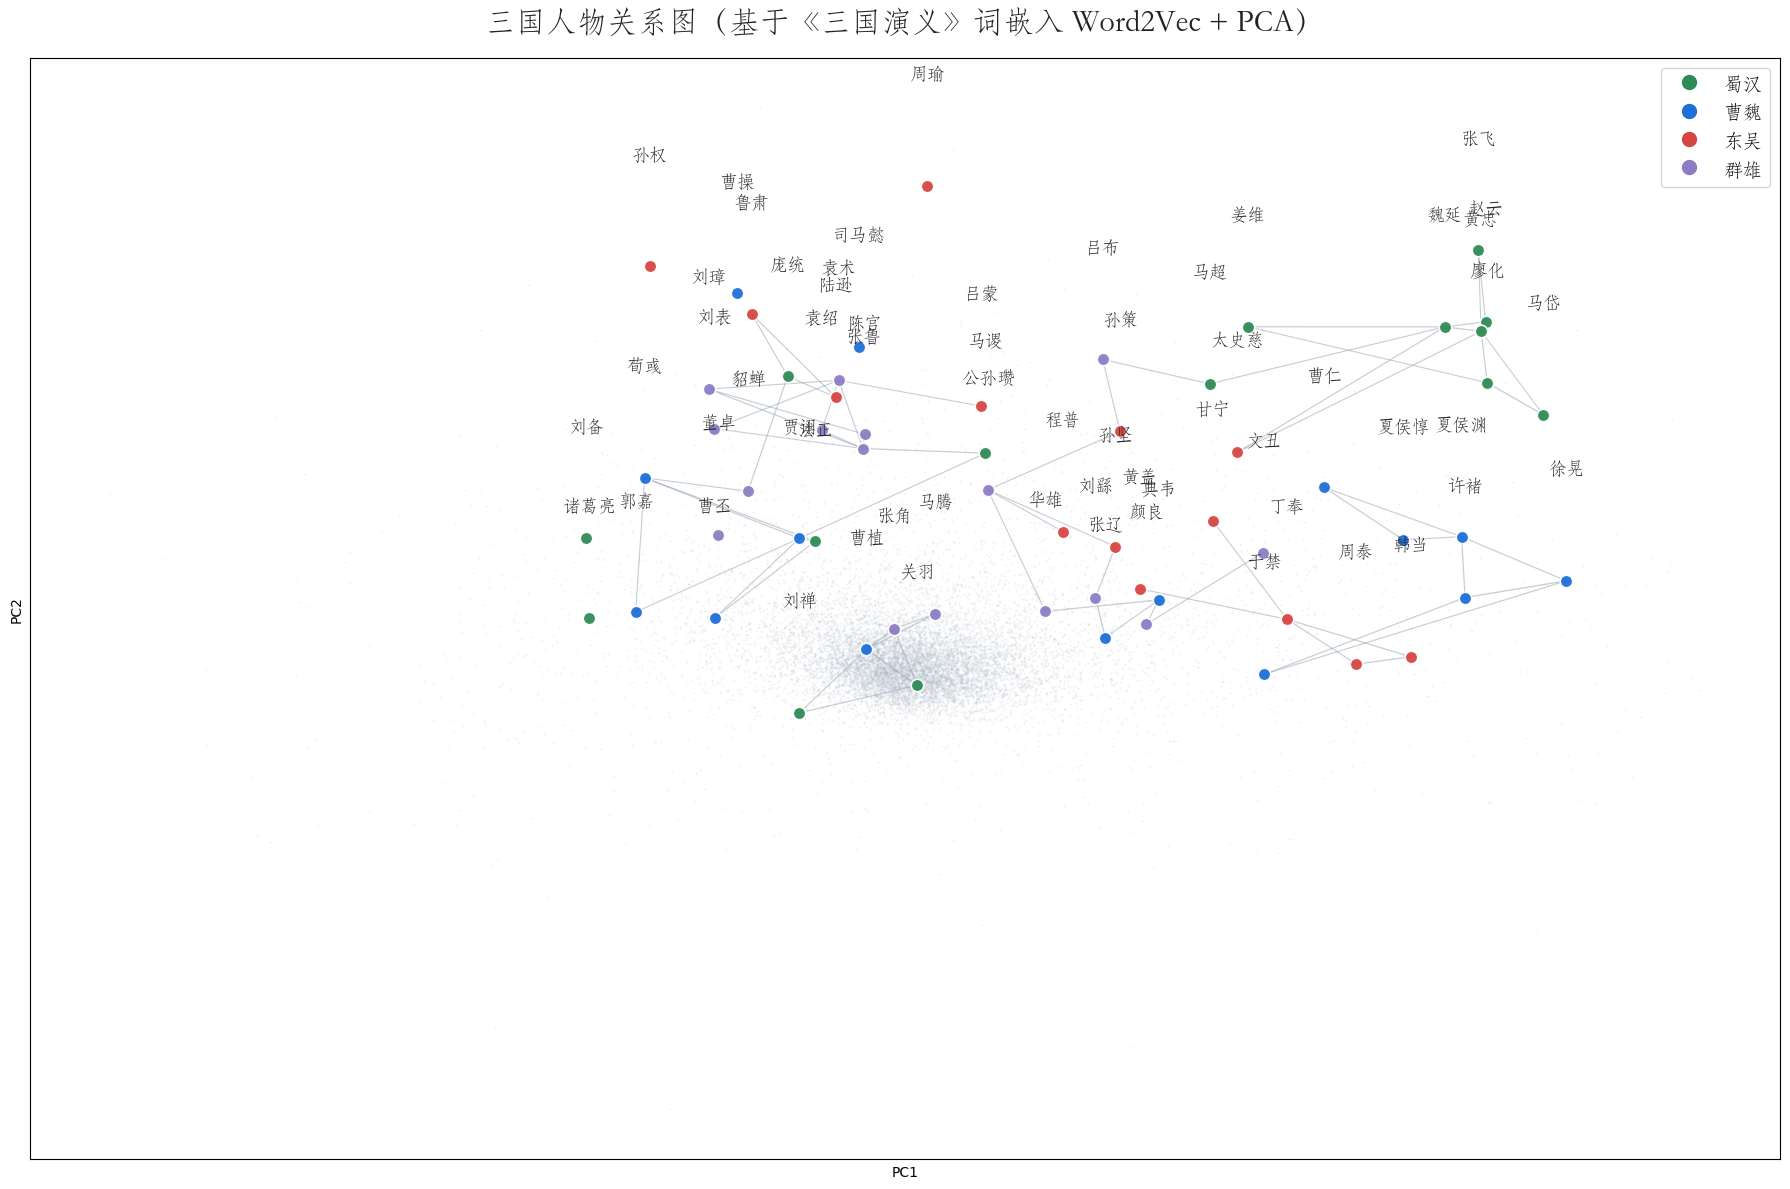

已保存: C:\Users\叶湘伦\Desktop\2026-2027-1专业实习Transformers预训练模型\三国\三国人物关系图.png


In [6]:
matplotlib.rcParams['axes.unicode_minus'] = False

if os.path.exists(FONT):
    zhfont = fm.FontProperties(fname=FONT, size=13)
    zhfont_title = fm.FontProperties(fname=FONT, size=22)
    zhfont_legend = fm.FontProperties(fname=FONT, size=14)
else:
    print("警告: 未找到", FONT, "，使用系统默认字体（中文可能乱码）")
    zhfont = fm.FontProperties(size=13)
    zhfont_title = fm.FontProperties(size=22)
    zhfont_legend = fm.FontProperties(size=14)

FACTION_COLOR = {"蜀汉": "#2E8B57", "曹魏": "#1E6FD9", "东吴": "#D64541", "群雄": "#8E7CC3"}

fig, ax = plt.subplots(figsize=(18, 12))
ax.set_facecolor("white")

raw_wordvec = np.array([model.wv.get_vector(w) for w in model.wv.index_to_key])
X_all = pca.transform(raw_wordvec)
ax.plot(X_all[:, 0], X_all[:, 1], '.', markersize=1, alpha=0.18, color='#AAB6C4')

for (i, j) in edges:
    s = edge_sims[(i, j)]
    alpha = min(0.55, 0.15 + s * 0.6)
    ax.plot([coords[i][0], coords[j][0]], [coords[i][1], coords[j][1]], '-',
            color='#9AA7B5', alpha=alpha, linewidth=0.8 + (s - THRESH) * 3)

for n in names:
    x, y = coords[names.index(n)]
    c = FACTION_COLOR[present[n]]
    ax.plot(x, y, 'o', markersize=9, color=c, alpha=0.95,
            markeredgecolor='white', markeredgewidth=1.2, zorder=3)
    ax.text(x, y + 0.35, n, fontproperties=zhfont, color='#222222',
            ha='center', va='bottom', zorder=4)

for fac, c in FACTION_COLOR.items():
    ax.plot([], [], 'o', color=c, label=fac, markersize=10)
ax.legend(prop=zhfont_legend, loc='upper right', frameon=True)
ax.set_title("三国人物关系图（基于《三国演义》词嵌入 Word2Vec + PCA）",
             fontproperties=zhfont_title, color='#222222', pad=20)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.savefig(OUT_PNG, dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("已保存:", OUT_PNG)


## 6. 保存数据与查看结果

将坐标、阵营、连线与 PCA 解释率保存为 JSON，并打印相似度最高的关系连线。


In [7]:
data = {
    "characters": names,
    "faction": present,
    "coords": coords.tolist(),
    "edges": [[names[i], names[j], round(edge_sims[(i, j)], 4)] for (i, j) in edges],
    "pca_explained": pca.explained_variance_ratio_.tolist(),
    "missing": missing,
}
with open(OUT_JSON, 'w', encoding='utf-8') as f:
    json.dump(data, f, ensure_ascii=False, indent=2)
print("已保存数据:", OUT_JSON)

print("\n>>> 相似度最高的关系连线 Top 15:")
for key, s in sorted(edge_sims.items(), key=lambda kv: kv[1], reverse=True)[:15]:
    i, j = key
    print(f"  {names[i]} — {names[j]}: {s:.4f}")


已保存数据: C:\Users\叶湘伦\Desktop\2026-2027-1专业实习Transformers预训练模型\三国\三国人物关系数据.json

>>> 相似度最高的关系连线 Top 15:
  张辽 — 刘繇: 0.9794
  许褚 — 徐晃: 0.9787
  曹植 — 张角: 0.9688
  廖化 — 马岱: 0.9680
  周泰 — 韩当: 0.9661
  荀彧 — 贾诩: 0.9641
  典韦 — 华雄: 0.9641
  关羽 — 曹植: 0.9639
  法正 — 贾诩: 0.9617
  陈宫 — 张鲁: 0.9605
  黄忠 — 魏延: 0.9594
  许褚 — 夏侯渊: 0.9582
  曹植 — 马腾: 0.9579
  关羽 — 张角: 0.9571
  张飞 — 赵云: 0.9533
